# A mixture: how much of each component, from one spectrum

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/11_a_mixture.ipynb)

The ten notebooks before this one predict a property of one object: a molecule, a catalyst, a
hop in a crystal. This one asks a different kind of question, the daily question of analytical
chemistry: a sample is a **mixture** of known substances, and its spectrum is measured. How much
of each substance does it hold?

The eighth notebook treated a spectrum as a field on a line. A mixture fits that picture well.
By the Beer-Lambert law the absorbance spectrum of a mixture is the sum of the spectra of its
components, each multiplied by its amount. A sum of fields is a field, and the kernel of the
spectra is linear in each of its two spectra. So the amounts can be learned by the same kernel
ridge regression, from mixtures of known composition, without the spectra of the pure
components.

The mixtures of this notebook are made in the notebook: the components are computed infrared
spectra of benzoic acids, the same file that the eighth notebook reads, and every mixture gets
a baseline and noise of its own. This has one large advantage for a lesson. The best error that
any method can reach is known, so the model can be compared with it.

Four questions are asked.

1. Does the model find the amounts, and how close does it come to the best possible error?
2. Is it better than partial least squares regression (PLS), the standard method of the field?
3. Which form of the kernel is right for amounts, and which for fractions?
4. What happens when the samples to predict have a baseline that the samples to fit did not
   have?

Running time: about one minute.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The components

Four benzoic acids are the components of the first example. Their stick spectra are put on one
axis, every stick as a Gaussian with a width of 6 cm⁻¹, and each curve is scaled so that its
strongest band is 1. That is the unit of every amount and every error below.

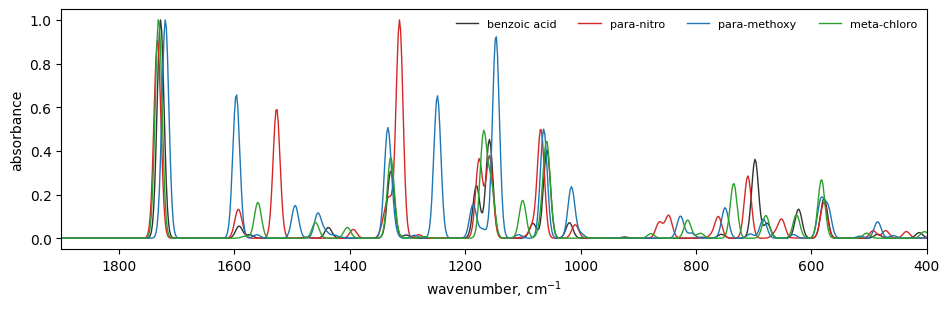

cosine kernel of two components: 0.30 to 0.85


In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from cmfqsar import spectrum as SP

with open("examples/spectra/benzoic_acids_ir.json", encoding="utf-8") as fh:
    acids = json.load(fh)["acids"]
names = [a["name"] for a in acids]
sticks = [SP.Spectrum(a["wavenumbers"], a["intensities"], "sticks", "wavenumber", a["name"]) for a in acids]

GRID = SP.Grid(400.0, 4000.0, 2.0)                # the axis of every curve of this notebook
x = GRID.x
pool = SP.feature_matrix(sticks, GRID, 6.0)       # all 189 acids as curves, one row each
pool = pool / pool.max(axis=1, keepdims=True)

chosen = ["H", "para-NO2", "para-OCH3", "meta-Cl"]
labels = ["benzoic acid", "para-nitro", "para-methoxy", "meta-chloro"]
colours = ["0.2", "tab:red", "tab:blue", "tab:green"]
S = pool[[names.index(n) for n in chosen]]

fig, ax = plt.subplots(figsize=(9.6, 3.2))
for row, label, colour in zip(S, labels, colours):
    ax.plot(x, row, color=colour, lw=1.0, label=label)
ax.set_xlim(1900, 400); ax.set_xlabel("wavenumber, cm$^{-1}$"); ax.set_ylabel("absorbance"); ax.legend(frameon=False, fontsize=8, ncol=4)
plt.tight_layout(); plt.show()
similar = SP.spectrum_kernel(S)
print("cosine kernel of two components: %.2f to %.2f" % (similar[np.triu_indices(4, 1)].min(), similar[np.triu_indices(4, 1)].max()))

The four acids are close relatives, and their spectra overlap: each has its carbonyl band near
1730 cm⁻¹ and ring bands at nearly the same places. So no component has a band of its own that
could simply be measured. This is the usual case, and it is the case in which a model of the
whole spectrum is needed.

## The kernel of a mixture is made of the kernels of its components

Before any mixture is simulated, one identity is checked. If the spectrum of a mixture is the
sum of the spectra of its components times their amounts, then the kernel of two mixtures is the
same sum over the kernels of the components. With the amounts as the rows of a matrix W and the
kernel K of the components, the kernel of the mixtures is W K Wᵀ.

`SP.mix` makes the spectrum of a mixture and `SP.mixture_kernel` computes that product. The two
ways must give the same matrix.

In [3]:
four = [sticks[names.index(n)] for n in chosen]
W = np.array([[1.0, 0.5, 0.0, 0.2],              # three mixtures: the amount of each component
              [0.1, 0.1, 1.2, 0.6],
              [0.4, 0.4, 0.4, 0.4]])
mixtures = [SP.mix(four, amounts) for amounts in W]

direct = SP.exact_kernel(mixtures, 6.0, normalize=False)                      # from the mixed spectra
from_parts = SP.mixture_kernel(SP.exact_kernel(four, 6.0, normalize=False), W)  # W K W^T
print("largest difference, relative to the largest element: %.0e" % (np.abs(direct - from_parts).max() / np.abs(direct).max()))

largest difference, relative to the largest element: 2e-16


The difference is rounding. Two things follow from the identity.

- An amount is a **linear** function of the spectrum. A kernel ridge model on the linear kernel
  can therefore represent it exactly, and nothing more flexible is needed while the Beer-Lambert
  law holds.
- The identity holds for the kernel that is **not normalised**. All earlier notebooks use the
  cosine form, which divides every spectrum by its length. That removes the total amount, which
  is the thing asked for here. The section on fractions below comes back to this.

## Simulated mixtures

A mixture is made as a real one would look. The fractions of the four components are drawn at
random, and the total amount is between 0.5 and 2. Every mixture gets a baseline of its own, an
offset of up to 0.2 and a straight rise or fall of up to 0.1 over the axis, and noise with a
standard deviation of 0.005. A baseline is what the instrument and the sample holder add; it is
not part of the substance.

There are 120 mixtures to fit the model and 120 others to test it.

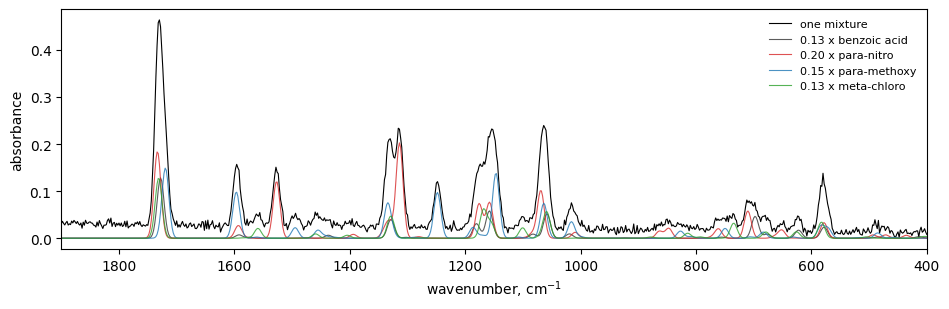

In [4]:
RAMP = np.linspace(-0.5, 0.5, len(x))


def make_mixtures(S, n, rng, baseline=True, noise=0.005):
    """n mixtures of the components S: their spectra and the amounts of the components."""
    fractions = rng.dirichlet(np.ones(len(S)), size=n)
    amounts = fractions * rng.uniform(0.5, 2.0, size=(n, 1))
    X = amounts @ S                                          # the Beer-Lambert law
    if baseline:
        X = X + rng.uniform(0.0, 0.2, size=(n, 1)) + rng.uniform(-0.1, 0.1, size=(n, 1)) * RAMP[None, :]
    return X + noise * rng.normal(size=X.shape), amounts


rng = np.random.RandomState(0)
X_fit, A_fit = make_mixtures(S, 120, rng)
X_test, A_test = make_mixtures(S, 120, rng)

fig, ax = plt.subplots(figsize=(9.6, 3.2))
ax.plot(x, X_fit[0], color="k", lw=0.8, label="one mixture")
for row, amount, label, colour in zip(S, A_fit[0], labels, colours):
    ax.plot(x, amount * row, color=colour, lw=0.8, alpha=0.8, label="%.2f x %s" % (amount, label))
ax.set_xlim(1900, 400); ax.set_xlabel("wavenumber, cm$^{-1}$"); ax.set_ylabel("absorbance"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

The black curve is what would be measured. It lies above the sum of its parts by its baseline.

## The model and two references

**The model** is kernel ridge regression on the linear kernel of the curves, not normalised, with
one output for each component. The ridge parameter is chosen on four folds inside the mixtures
to fit. The model sees 120 spectra with their compositions. It is not told the spectra of the
pure components, and it is not told that there is a baseline.

**The first reference is the best possible answer.** If the spectra of the pure components are
known, every mixture can be fitted by least squares with those four spectra, a constant and a
straight line. With a linear response and this kind of noise no estimate from one spectrum is
better. A model that has to learn from mixtures cannot pass it. It is called the floor below.

**The second reference is PLS**, partial least squares regression, which is how such amounts are
found in practice. It gets the same curves, and its number of components is chosen on the same
folds.

error of the amounts on the 120 test mixtures (root mean square)
   the floor: least squares with the pure spectra   0.0024
   kernel ridge on the linear kernel                0.0026
   PLS                                              0.0025


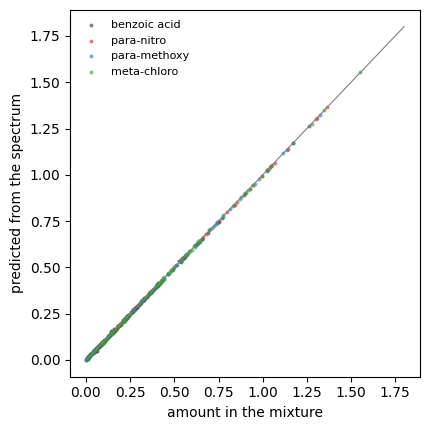

In [5]:
from sklearn.cross_decomposition import PLSRegression

RIDGES = tuple(10.0 ** p for p in range(-9, 1))


def rows(X, form="plain", cosine=False, width=0.0):
    """The curves as the rows of a description: as they are or as their slopes along the axis
    (after a smoothing of the given width), and each divided by its length for the cosine form."""
    F = SP.smoothed(X, GRID.step, width) if width > 0 else np.asarray(X, float)
    if form == "slope":
        F = SP.slope(F, GRID)
    return F / np.linalg.norm(F, axis=1)[:, None] if cosine else F


def ridge_fit(F, Y, ridge):
    """Kernel ridge regression with a constant on the linear kernel of the rows F.
    Returns a function that predicts, and the weight of the model over the axis."""
    mean, y_mean = F.mean(axis=0), Y.mean(axis=0)
    centred = F - mean
    K = centred @ centred.T
    coefficients = np.linalg.solve(K + ridge * np.trace(K) / len(K) * np.eye(len(K)), Y - y_mean)
    weight = centred.T @ coefficients                # one curve over the axis for every output
    return (lambda G: (G - mean) @ weight + y_mean), weight


def choose(fit_one, settings, F, Y, rng, folds=4):
    """The setting with the lowest error on folds inside the mixtures to fit."""
    parts = np.array_split(rng.permutation(len(Y)), folds)
    errors = []
    for setting in settings:
        error = 0.0
        for part in parts:
            train = np.setdiff1d(np.arange(len(Y)), part)
            error += np.sum((fit_one(setting, F[train], Y[train])(F[part]) - Y[part]) ** 2)
        errors.append(error)
    return settings[int(np.argmin(errors))]


def kernel_model(F, Y, rng):
    ridge = choose(lambda r, f, y: ridge_fit(f, y, r)[0], RIDGES, F, Y, rng)
    return ridge_fit(F, Y, ridge)


def slope_model(X, Y, rng):
    """The same model on the slopes of the curves. A derivative makes noise larger, so the
    curves are smoothed first, and the width of the smoothing is chosen with the ridge."""
    def fit(setting, X_train, Y_train):
        width, ridge = setting
        model = ridge_fit(rows(X_train, "slope", width=width), Y_train, ridge)[0]
        return lambda X_new: model(rows(X_new, "slope", width=width))
    settings = [(width, ridge) for width in (0.0, 8.0, 16.0) for ridge in RIDGES]
    return fit(choose(fit, settings, X, Y, rng), X, Y)


def pls_model(F, Y, rng):
    fit = lambda k, f, y: PLSRegression(n_components=k, scale=False).fit(f, y).predict
    return fit(choose(fit, tuple(range(1, 11)), F, Y, rng), F, Y)


def floor(X, S):
    """The amounts from a least-squares fit with the known pure spectra and a baseline."""
    design = np.vstack([S, np.ones(len(x)), RAMP]).T
    return np.linalg.lstsq(design, X.T, rcond=None)[0][: len(S)].T


def rmse(predicted, true):
    return float(np.sqrt(np.mean((predicted - true) ** 2)))


predict, weight = kernel_model(rows(X_fit), A_fit, rng)
predict_pls = pls_model(rows(X_fit), A_fit, rng)
print("error of the amounts on the 120 test mixtures (root mean square)")
print("   the floor: least squares with the pure spectra   %.4f" % rmse(floor(X_test, S), A_test))
print("   kernel ridge on the linear kernel                %.4f" % rmse(predict(rows(X_test)), A_test))
print("   PLS                                              %.4f" % rmse(predict_pls(rows(X_test)), A_test))

fig, ax = plt.subplots(figsize=(4.4, 4.4))
P = predict(rows(X_test))
for k, (label, colour) in enumerate(zip(labels, colours)):
    ax.scatter(A_test[:, k], P[:, k], s=8, color=colour, alpha=0.6, lw=0, label=label)
ax.plot([0, 1.8], [0, 1.8], color="0.5", lw=0.8)
ax.set_xlabel("amount in the mixture"); ax.set_ylabel("predicted from the spectrum"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

The amounts run from 0 to nearly 2, and the model finds them to about 0.002. The three numbers
are close to each other. One example cannot say how close, so the experiment is repeated: ten
times with four other acids drawn from the 189, new mixtures and new noise. The same loop also
runs the variants that the next sections need.

In [6]:
def fractions(amounts):
    return amounts / amounts.sum(axis=1, keepdims=True)


REPEATS = 10
errors = {}
for repeat in range(REPEATS):
    rng = np.random.RandomState(100 + repeat)
    S_r = pool[rng.choice(len(pool), 4, replace=False)]
    Xf, Af = make_mixtures(S_r, 120, rng)
    Xt, At = make_mixtures(S_r, 120, rng)
    Xf_flat, Af_flat = make_mixtures(S_r, 120, rng, baseline=False)      # for the section on the baseline
    out = {"floor": rmse(floor(Xt, S_r), At), "floor, fractions": rmse(fractions(floor(Xt, S_r)), fractions(At))}

    model, _ = kernel_model(rows(Xf), Af, rng)
    out["kernel"] = rmse(model(rows(Xt)), At)
    out["kernel, divided by the sum"] = rmse(fractions(model(rows(Xt))), fractions(At))
    out["PLS"] = rmse(pls_model(rows(Xf), Af, rng)(rows(Xt)), At)

    model, _ = kernel_model(rows(Xf, cosine=True), Af, rng)              # the cosine form, for amounts
    out["cosine, amounts"] = rmse(model(rows(Xt, cosine=True)), At)
    model, _ = kernel_model(rows(Xf, cosine=True), fractions(Af), rng)   # the cosine form, for fractions
    out["cosine, fractions"] = rmse(model(rows(Xt, cosine=True)), fractions(At))

    out["slope"] = rmse(slope_model(Xf, Af, rng)(Xt), At)                # slopes, baseline in the fit
    model, _ = kernel_model(rows(Xf_flat), Af_flat, rng)                 # no baseline in the fit
    out["new baseline, plain"] = rmse(model(rows(Xt)), At)
    out["new baseline, PLS"] = rmse(pls_model(rows(Xf_flat), Af_flat, rng)(rows(Xt)), At)
    out["new baseline, slope"] = rmse(slope_model(Xf_flat, Af_flat, rng)(Xt), At)
    for key, value in out.items():
        errors.setdefault(key, []).append(value)
errors = {key: np.array(value) for key, value in errors.items()}


def interval(values, runs=5000, seed=0):
    """The mean with a 95 % interval from a bootstrap over the repeats."""
    draws = np.random.RandomState(seed).choice(values, (runs, len(values))).mean(axis=1)
    return "%+.5f [%+.5f, %+.5f]" % (values.mean(), np.percentile(draws, 2.5), np.percentile(draws, 97.5))


print("error of the amounts, mean of %d repeats" % REPEATS)
for key in ("floor", "kernel", "PLS"):
    print("   %-8s %.4f   %.2f times the floor" % (key, errors[key].mean(), (errors[key] / errors["floor"]).mean()))
print()
print("kernel minus PLS:       ", interval(errors["kernel"] - errors["PLS"]))
print("kernel minus the floor: ", interval(errors["kernel"] - errors["floor"]))

error of the amounts, mean of 10 repeats
   floor    0.0022   1.00 times the floor
   kernel   0.0023   1.06 times the floor
   PLS      0.0023   1.05 times the floor

kernel minus PLS:        +0.00003 [+0.00002, +0.00004]
kernel minus the floor:  +0.00013 [+0.00011, +0.00016]


**Question 1: yes.** The model finds the amounts with an error a few per cent above the floor.
It was not given the pure spectra, and the floor was. So what is lost by learning the components
from 120 mixtures, with a baseline to learn as well, is small.

**Question 2: no.** The kernel model and PLS give the same error to three decimals. PLS is ahead
by 0.00003, about one per cent of the error. The interval of that difference excludes zero, so
it is real, and it is far too small to matter. This is the expected result and not a
disappointment. The problem is linear, both
methods fit a linear model, and with enough mixtures both find it. The kernel method is not a
better tool for this task than PLS. What it adds is that the task is done with the same objects
as the rest of the program: the same kernel, and a weight over the axis that can be read, as the
last section shows.

## Amounts and fractions: when not to normalise

Often the question is the composition and not the amount: which fraction of the sample is each
component. The fraction does not depend on how much sample is in the beam.

The cosine form of the kernel divides every spectrum by its length, so it removes the total
amount too. It looks like the right form for fractions, and it is the form of all earlier
notebooks. The loop above ran it for both questions, and it also ran the simple alternative:
predict the amounts with the kernel that is not normalised, and divide them by their sum.

In [7]:
print("amounts")
for key, label in (("kernel", "not normalised"), ("cosine, amounts", "cosine form")):
    print("   %-44s %.4f   %5.1f times the floor" % (label, errors[key].mean(), (errors[key] / errors["floor"]).mean()))
print("fractions")
for key, label in (("kernel, divided by the sum", "not normalised, amounts divided by their sum"), ("cosine, fractions", "cosine form")):
    print("   %-44s %.4f   %5.1f times the floor" % (label, errors[key].mean(), (errors[key] / errors["floor, fractions"]).mean()))

amounts
   not normalised                               0.0023     1.1 times the floor
   cosine form                                  0.1281    62.9 times the floor
fractions
   not normalised, amounts divided by their sum 0.0024     1.1 times the floor
   cosine form                                  0.0658    32.2 times the floor


**Question 3.** For amounts the cosine form fails, as it must: the information was divided out,
and the error is about sixty times the floor. For fractions it is also poor, and that is less
obvious. The reason is that the length of a spectrum is not proportional to the total amount.
It depends on which components are in the mixture, because their bands differ in strength, and
here it also holds the baseline. So dividing by the length does not divide by the amount.

The rule is short. Use the kernel that is not normalised for amounts, and for fractions too, by
dividing the predicted amounts by their sum. Keep the cosine form for questions where only the
shape of the spectrum is known, such as the property of a compound in the eighth notebook.

## A baseline that the model has not seen

In all runs above the mixtures to fit had baselines, and the model learned to ignore them. A
harder case is closer to practice: the model is fitted on clean spectra, and the samples to
predict come from another day, another cell or another instrument, with a baseline. The loop
above made that case too.

The standard repair is to describe every spectrum by its **slope** along the axis in place of
its values (`SP.slope`). A constant offset has no slope. A derivative makes noise larger, so the
curve is smoothed before its slope is taken, and the width of the smoothing is chosen on the
folds together with the ridge parameter.

In [8]:
print("%-58s %10s %22s" % ("", "error", "times the floor"))
for key, label in (("kernel", "baseline in the mixtures to fit: the curves"),
                   ("slope", "baseline in the mixtures to fit: their slopes"),
                   ("new baseline, plain", "baseline only in the test mixtures: the curves"),
                   ("new baseline, PLS", "baseline only in the test mixtures: the curves, PLS"),
                   ("new baseline, slope", "baseline only in the test mixtures: their slopes")):
    print("%-58s %10.4f %22.1f" % (label, errors[key].mean(), (errors[key] / errors["floor"]).mean()))

                                                                error        times the floor
baseline in the mixtures to fit: the curves                    0.0023                    1.1
baseline in the mixtures to fit: their slopes                  0.0028                    1.3
baseline only in the test mixtures: the curves                 0.1747                   80.0
baseline only in the test mixtures: the curves, PLS            0.1746                   79.9
baseline only in the test mixtures: their slopes               0.0027                    1.2


**Question 4.** With the curves as they are, the model fails on a baseline that it has not
seen: the error is about eighty times the floor, and PLS fails in the same way. With slopes the
error stays near the floor. When the baseline is already in the mixtures to fit, the slopes cost
a little, because a derivative makes noise larger.

So the choice between the curve and its slope is a question about the samples, and the eighth
notebook met the same question in another form: a model reads the spectra of the kind that it
was fitted on. If the new samples can differ in something that is not chemistry, either show
that difference to the model in the samples to fit, or describe the spectra in a way that does
not see it.

## The co-spectrum of an amount

The model for one component is a constant plus the integral of a weight over the axis times the
spectrum. This weight is the co-spectrum of the eighth notebook, and `ridge_fit` returned it.

For an amount it has a known meaning. Chemometrics calls the part of the spectrum of a
component that no combination of the other components and of the baseline can make its **net
analyte signal**. It is the only part from which the amount of that component can be read. The
cell computes it from the pure spectra, which the model never saw, and compares it with the
weight of the model.

cosine between the weight of the model and the net signal of the component
   benzoic acid   0.96
   para-nitro     0.96
   para-methoxy   0.97
   meta-chloro    0.96


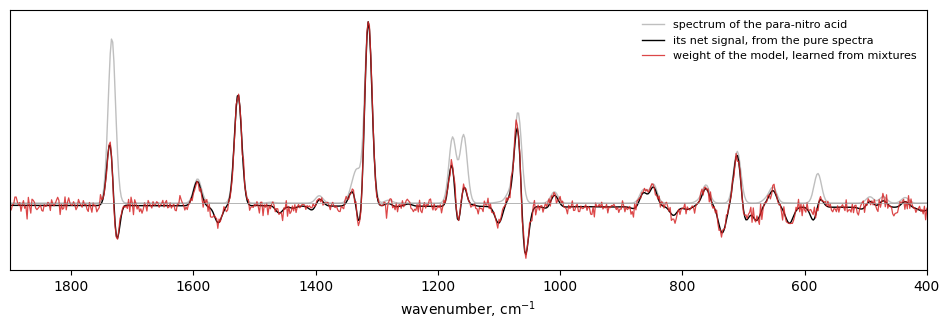

In [9]:
def net_signal(S, k):
    """The part of component k that the other components and a baseline cannot make."""
    rest = np.vstack([np.delete(S, k, axis=0), np.ones(len(x)), RAMP])
    return S[k] - rest.T @ np.linalg.lstsq(rest.T, S[k], rcond=None)[0]


print("cosine between the weight of the model and the net signal of the component")
for k, label in enumerate(labels):
    net = net_signal(S, k)
    print("   %-14s %.2f" % (label, net @ weight[:, k] / np.linalg.norm(net) / np.linalg.norm(weight[:, k])))

k = 1
net = net_signal(S, k)
fig, ax = plt.subplots(figsize=(9.6, 3.4))
ax.plot(x, S[k] / S[k].max(), color="0.75", lw=1.0, label="spectrum of the %s acid" % labels[k])
ax.plot(x, net / np.abs(net).max(), color="k", lw=1.0, label="its net signal, from the pure spectra")
ax.plot(x, weight[:, k] / np.abs(weight[:, k]).max(), color="tab:red", lw=0.9, alpha=0.85, label="weight of the model, learned from mixtures")
ax.axhline(0.0, color="0.6", lw=0.5)
ax.set_xlim(1900, 400); ax.set_xlabel("wavenumber, cm$^{-1}$"); ax.set_yticks([]); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

The weight that the model learned from mixtures is nearly the net signal that follows from the
pure spectra. It can be read as a spectrum. It is positive at the bands of the component that
the other components do not cover, and negative where a band of another component has to be
taken off. At the carbonyl band, which all four acids share, it changes sign within a few
wavenumbers: only the small differences in position can be used there.

## What this notebook does not show

- **The mixtures are simulated.** Real mixtures were not used, and the repository holds no
  measured set that may be copied. In a real solution the bands of a component move and widen
  with the composition, and the Beer-Lambert law fails at high absorbance. The manual has one
  such case, a detector that saturates; there the models that learn from mixtures are far better
  than the fit with the pure spectra, because that fit assumes a linear response.
- **Four components, all known to be present.** A component that the model has not seen is a
  different problem.

## What to take from this notebook

- The spectrum of a mixture is a sum of fields, and the kernel of mixtures is W K Wᵀ. An amount
  is a linear function of the spectrum.
- On a linear problem the kernel model equals PLS, and both come within a few per cent of the
  best possible error. Say so, and do not look for a gain where there is none.
- Do not normalise when the question is an amount. For fractions, divide the predicted amounts
  by their sum.
- A baseline that the model has not seen makes it fail. The slope of the spectrum does not see
  an offset.
- The weight of a model for an amount is the net signal of the component. It can be read, and
  it can be checked against the pure spectra when they are known.

The functions for spectra are a Python module; the `cmf` command has no mode for them yet.

Where to read further in the manual: *Mixtures and quantification: the spectrum of a mixture as
a sum of fields* has the full measurement, with measured spectra as the components and the case
of a saturating detector, and *Two instruments: a model fitted on one instrument reads the
spectra of another* treats the transfer of a model between instruments.